In [1]:

import os, cv2, numpy as np, matplotlib.pyplot as plt
plt.rcParams['figure.dpi']=110


In [2]:

def show(imgs, titles=None, cmap='gray', figsize=(12,4), suptitle=None):
    n=len(imgs); fig,axes=plt.subplots(1,n,figsize=figsize);
    if n==1: axes=[axes]
    if suptitle: fig.suptitle(suptitle)
    for ax,im,t in zip(axes,imgs,(titles or [""]*n)):
        ax.imshow(im, cmap=cmap); ax.set_title(t); ax.axis('off')
    plt.show()

In [3]:
def to_float01(img):
    img=np.asarray(img).astype(np.float32)
    if img.max()>1.0: img/=255.0
    if img.ndim==3: img=cv2.cvtColor(img,cv2.COLOR_BGR2GRAY)
    return img

In [4]:

def save(path,img): cv2.imwrite(path, np.clip((img*255).astype(np.uint8),0,255))

In [5]:
img_path1='radiografia.jpg'; img_path2='corte.jpg'

In [6]:

img1 = cv2.imread(img_path1, cv2.IMREAD_GRAYSCALE) if os.path.exists(img_path1) else None
img2 = cv2.imread(img_path2, cv2.IMREAD_GRAYSCALE) if os.path.exists(img_path2) else None
if img1 is None or img2 is None:
    print('AVISO: coloque radiografia.jpg y corte.jpg en la carpeta o actualice las rutas')

In [7]:

if img1 is not None: img1 = to_float01(img1)
if img2 is not None: img2 = to_float01(img2)

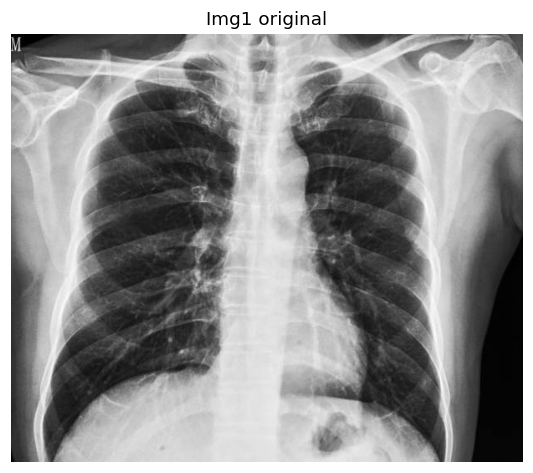

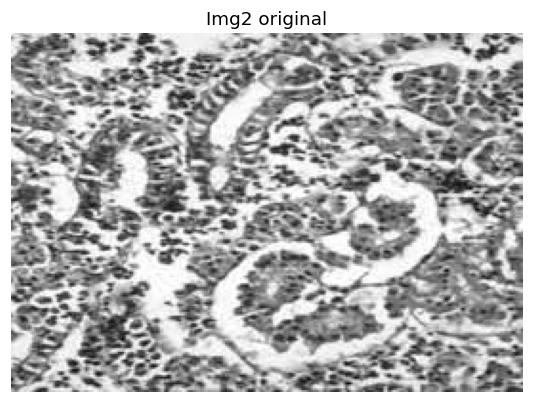

In [8]:

if img1 is not None: show([img1],['Img1 original'],figsize=(6,6))
if img2 is not None: show([img2],['Img2 original'],figsize=(6,6))

### 1. Funciones de Suavizado y Reducción de Ruido
Definimos filtros espaciales (Promedio, Gaussiano y Mediana) utilizando distintos tamaños de ventana para reducir el ruido en las imágenes.

In [22]:
def suavizar_imagen(imagen):
    matriz_uint8 = (imagen * 255).astype(np.uint8)
    ventanas = [3, 5, 11]
    resultados = {}
    for v in ventanas:
        resultados[f'promedio_{v}'] = cv2.blur(matriz_uint8, (v, v)).astype(np.float32) / 255.0
        resultados[f'gauss_{v}'] = cv2.GaussianBlur(matriz_uint8, (v, v), 0).astype(np.float32) / 255.0
        resultados[f'mediana_{v}'] = cv2.medianBlur(matriz_uint8, v).astype(np.float32) / 255.0
    return resultados

### 2. Algoritmos de Detección de Bordes
Aplicamos operadores diferenciales espaciales (Sobel, Laplaciano y Kirsch) para resaltar transiciones rápidas de intensidad y delinear contornos.

In [23]:
def detectar_bordes(imagen):
    m_u8 = (imagen * 255).astype(np.uint8)
    dx = cv2.Sobel(m_u8, cv2.CV_64F, 1, 0, ksize=3)
    dy = cv2.Sobel(m_u8, cv2.CV_64F, 0, 1, ksize=3)
    grad_mag = np.hypot(dx, dy)
    laplaciano = np.abs(cv2.Laplacian(m_u8, cv2.CV_64F))

    # Máscaras de Kirsch orientadas en 8 direcciones
    kirsch_kernels = [
        np.array([[5, 5, 5], [-3, 0, -3], [-3, -3, -3]], np.float32),
        np.array([[5, 5, -3], [5, 0, -3], [-3, -3, -3]], np.float32),
        np.array([[5, -3, -3], [5, 0, -3], [5, -3, -3]], np.float32),
        np.array([[-3, -3, -3], [5, 0, -3], [5, 5, -3]], np.float32),
        np.array([[-3, -3, -3], [-3, 0, -3], [5, 5, 5]], np.float32),
        np.array([[-3, -3, -3], [-3, 0, 5], [-3, 5, 5]], np.float32),
        np.array([[-3, -3, 5], [-3, 0, 5], [-3, -3, 5]], np.float32),
        np.array([[-3, 5, 5], [-3, 0, 5], [-3, -3, -3]], np.float32)
    ]
    respuestas = [cv2.filter2D(m_u8.astype(np.float32), -1, k) for k in kirsch_kernels]
    borde_kirsch = np.max(np.stack(respuestas), axis=0)

    def normalizar(canal):
        canal = canal - canal.min()
        return canal / (canal.max() if canal.max() != 0 else 1.0)

    return {
        'sobel_horizontal': normalizar(np.abs(dx)),
        'sobel_vertical': normalizar(np.abs(dy)),
        'magnitud_sobel': normalizar(grad_mag),
        'laplaciano': normalizar(laplaciano),
        'kirsch_final': normalizar(borde_kirsch)
    }

### 3. Transformada de Fourier y Filtros en Frecuencia
Implementamos la transición al dominio de la frecuencia mediante la FFT, permitiendo la creación de máscaras personalizadas (pasa-bajas, pasa-altas, anillos y bandas).

In [24]:
def transformada_fourier(imagen):
    espectro = np.fft.fftshift(np.fft.fft2(imagen))
    magnitud_log = np.log1p(np.abs(espectro))
    magnitud_norm = (magnitud_log - magnitud_log.min()) / (magnitud_log.max() - magnitud_log.min() if magnitud_log.max() != magnitud_log.min() else 1.0)
    return espectro, magnitud_norm

def transformada_inversa(espectro_desplazado):
    inversa = np.fft.ifft2(np.fft.ifftshift(espectro_desplazado))
    canal_real = np.real(inversa)
    canal_real = canal_real - canal_real.min()
    return canal_real / (canal_real.max() if canal_real.max() != 0 else 1.0)

def mascara_circular(dimensiones, radio):
    alto, ancho = dimensiones
    centro_y, centro_x = alto // 2, ancho // 2
    Y, X = np.ogrid[:alto, :ancho]
    mascara = ((Y - centro_y)**2 + (X - centro_x)**2) <= radio**2
    return mascara.astype(np.float32)

def mascara_anular(dimensiones, radio_interno, radio_externo):
    alto, ancho = dimensiones
    centro_y, centro_x = alto // 2, ancho // 2
    Y, X = np.ogrid[:alto, :ancho]
    distancia = np.sqrt((Y - centro_y)**2 + (X - centro_x)**2)
    mascara = (distancia >= radio_interno) & (distancia <= radio_externo)
    return mascara.astype(np.float32)

def mascara_cruz(dimensiones, grosor=5):
    alto, ancho = dimensiones
    centro_y, centro_x = alto // 2, ancho // 2
    mascara = np.zeros(dimensiones, np.float32)
    mascara[centro_y - grosor : centro_y + grosor + 1, :] = 1.0
    mascara[:, centro_x - grosor : centro_x + grosor + 1] = 1.0
    return mascara

### 4. Filtrado Espectral Genérico
Aplicamos cualquier máscara binaria definida sobre el espectro de la imagen de entrada para reconstruir la imagen filtrada.

In [25]:
def aplicar_filtro_frecuencia(imagen, mascara):
    esp, mag_orig = transformada_fourier(imagen)
    esp_filtrado = esp * mascara
    img_reconstruida = transformada_inversa(esp_filtrado)
    mag_filtrada = np.log1p(np.abs(esp_filtrado))
    mag_filtrada_norm = (mag_filtrada - mag_filtrada.min()) / (mag_filtrada.max() - mag_filtrada.min() if mag_filtrada.max() != mag_filtrada.min() else 1.0)
    return img_reconstruida, mag_orig, mag_filtrada_norm, mascara

### 5. Pruebas y Visualización de Resultados
Finalmente, ejecutamos el flujo completo para comprobar visualmente los efectos de los filtros espaciales y frecuenciales sobre nuestras imágenes de prueba.

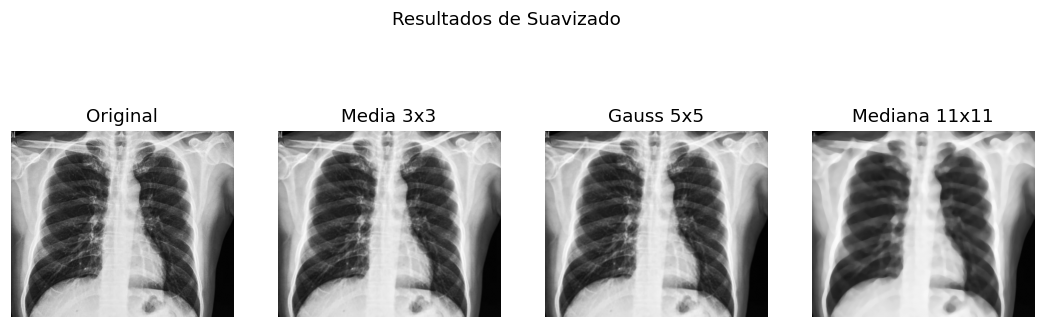

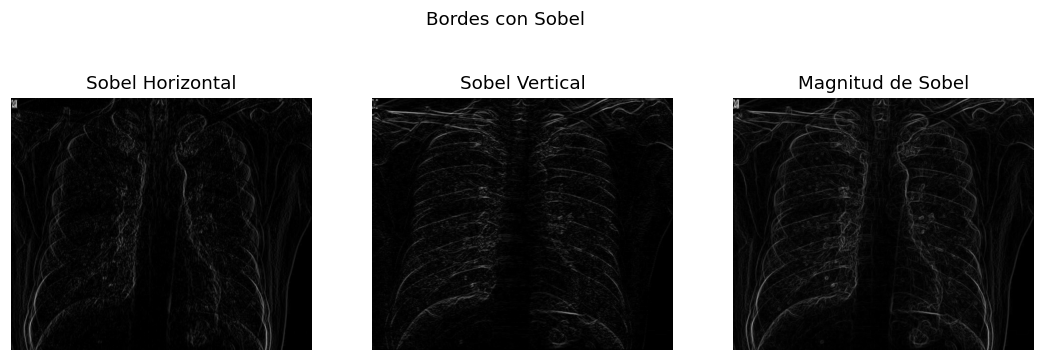

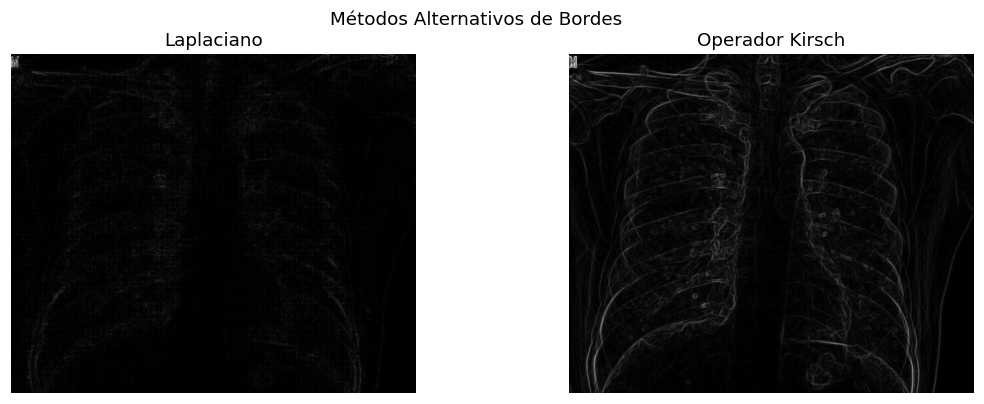

In [26]:
if img1 is not None:
    # Suavizados
    bloques_suaves = suavizar_imagen(img1)
    show([img1, bloques_suaves['promedio_3'], bloques_suaves['gauss_5'], bloques_suaves['mediana_11']],
         ['Original', 'Media 3x3', 'Gauss 5x5', 'Mediana 11x11'],
         suptitle='Resultados de Suavizado')

    # Bordes
    bloques_bordes = detectar_bordes(img1)
    show([bloques_bordes['sobel_horizontal'], bloques_bordes['sobel_vertical'], bloques_bordes['magnitud_sobel']],
         ['Sobel Horizontal', 'Sobel Vertical', 'Magnitud de Sobel'],
         suptitle='Bordes con Sobel')
    show([bloques_bordes['laplaciano'], bloques_bordes['kirsch_final']],
         ['Laplaciano', 'Operador Kirsch'],
         suptitle='Métodos Alternativos de Bordes')

In [9]:
def smoothing(img):
    u=(img*255).astype(np.uint8)
    sizes=[3,5,11]
    out={}
    for k in sizes:
        out[f'media_{k}']=cv2.blur(u,(k,k)).astype(np.float32)/255.0
        out[f'gauss_{k}']=cv2.GaussianBlur(u,(k,k),0).astype(np.float32)/255.0
        out[f'mediana_{k}']=cv2.medianBlur(u,k).astype(np.float32)/255.0
    return out

In [11]:
def edges(img):
    u=(img*255).astype(np.uint8)
    sx=cv2.Sobel(u,cv2.CV_64F,1,0,ksize=3); sy=cv2.Sobel(u,cv2.CV_64F,0,1,ksize=3)
    lap=np.abs(cv2.Laplacian(u,cv2.CV_64F))
    sobmag=np.hypot(sx,sy)
    # Kirsch: 8 máscaras direccionales
    K=[np.array([[5,5,5],[-3,0,-3],[-3,-3,-3]],np.float32),
        np.array([[5,5,-3],[5,0,-3],[-3,-3,-3]],np.float32),
        np.array([[5,-3,-3],[5,0,-3],[5,-3,-3]],np.float32),
        np.array([[-3,-3,-3],[5,0,-3],[5,5,-3]],np.float32),
        np.array([[-3,-3,-3],[-3,0,-3],[5,5,5]],np.float32),
        np.array([[-3,-3,-3],[-3,0,5],[-3,5,5]],np.float32),
        np.array([[-3,-3,5],[-3,0,5],[-3,-3,5]],np.float32),
        np.array([[-3,5,5],[-3,0,5],[-3,-3,-3]],np.float32)]
    kr=[cv2.filter2D(u.astype(np.float32),-1,k) for k in K]
    kir=np.max(np.stack(kr),axis=0)
    def norm(a): a=a-a.min(); return a/(a.max() if a.max()!=0 else 1)
    return {'sobelx':norm(np.abs(sx)),'sobely':norm(np.abs(sy)),'sobel_mag':norm(sobmag),'lap':norm(lap),'kirsch':norm(kir)}

In [12]:

def apply_kernel(img,kernel):
    u=(img*255).astype(np.uint8)
    r=cv2.filter2D(u.astype(np.float32),-1,kernel)
    r=r-r.min(); return r/(r.max() if r.max()!=0 else 1)

In [13]:

if img1 is not None:
    sm=smoothing(img1)

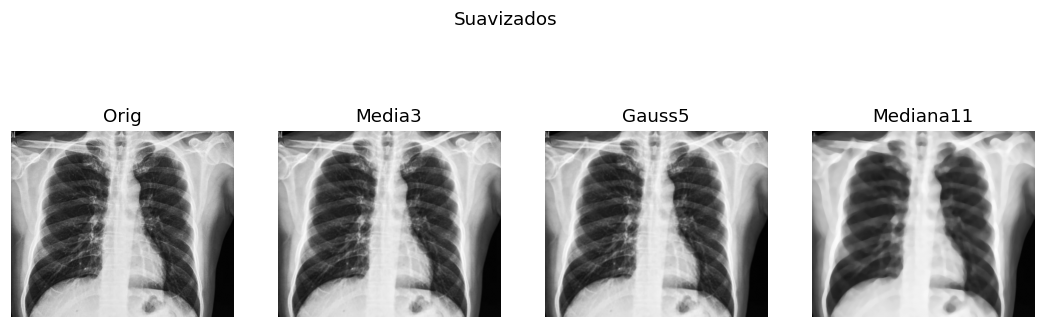

In [14]:
show([img1,sm['media_3'],sm['gauss_5'],sm['mediana_11']], ['Orig','Media3','Gauss5','Mediana11'], suptitle='Suavizados')
ed=edges(img1)

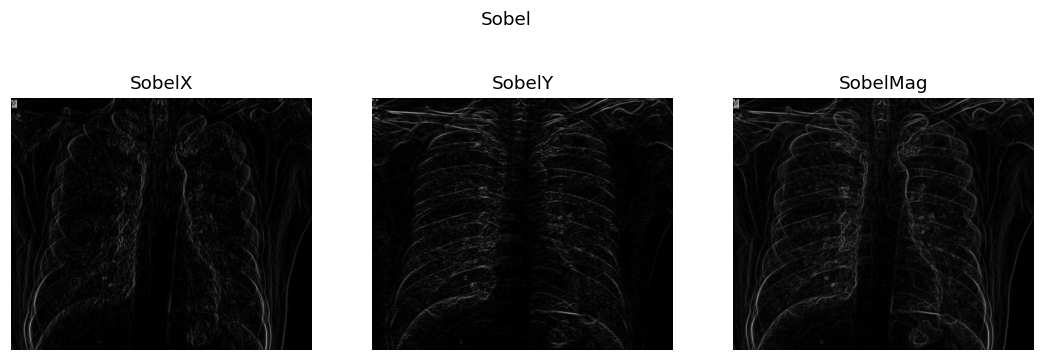

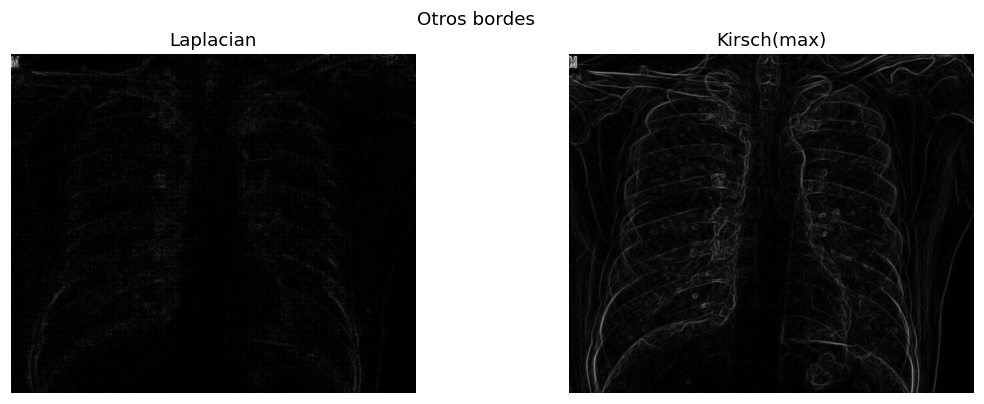

In [15]:
show([ed['sobelx'],ed['sobely'],ed['sobel_mag']],['SobelX','SobelY','SobelMag'], suptitle='Sobel')
show([ed['lap'],ed['kirsch']],['Laplacian','Kirsch(max)'], suptitle='Otros bordes')

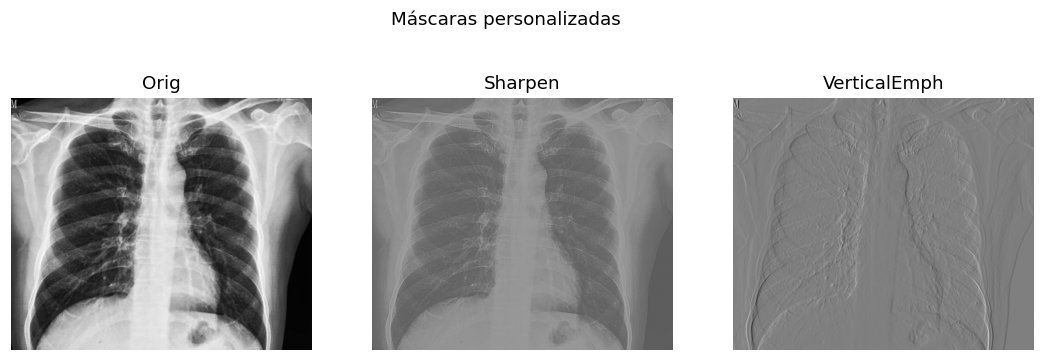

In [16]:
custom_sh=np.array([[0,-1,0],[-1,5,-1],[0,-1,0]],np.float32)
custom_vert=np.array([[-1,0,1],[-2,0,2],[-1,0,1]],np.float32)
show([img1,apply_kernel(img1,custom_sh),apply_kernel(img1,custom_vert)],['Orig','Sharpen','VerticalEmph'], suptitle='Máscaras personalizadas')

In [17]:
def fft(img):
    F=np.fft.fftshift(np.fft.fft2(img)); M=np.log1p(np.abs(F)); M=(M-M.min())/(M.max()-M.min() if M.max()!=M.min() else 1)
    return F,M
def ifft(Fshift):
    f=np.fft.ifft2(np.fft.ifftshift(Fshift)); r=np.real(f); r=r-r.min(); return r/(r.max() if r.max()!=0 else 1)

In [18]:
def circ_mask(shape,r):
    rows,cols=shape; cy, cx=rows//2, cols//2; Y,X=np.ogrid[:rows,:cols]; m=((Y-cy)**2+(X-cx)**2)<=r*r; return m.astype(np.float32)

def ring_mask(shape,ri,ro):
    rows,cols=shape; cy, cx=rows//2, cols//2; Y,X=np.ogrid[:rows,:cols]; d=np.sqrt((Y-cy)**2+(X-cx)**2); m=(d>=ri)&(d<=ro); return m.astype(np.float32)

def cross_mask(shape,th=5):
    rows,cols=shape; cy, cx=rows//2, cols//2; m=np.zeros(shape,np.float32); m[cy-th:cy+th+1,:]=1; m[:,cx-th:cx+th+1]=1; return m

In [19]:
def apply_freq(img,mask):
    F,M=fft(img); Fm=F*mask; imgb=ifft(Fm); Mm=np.log1p(np.abs(Fm)); Mm=(Mm-Mm.min())/(Mm.max()-Mm.min() if Mm.max()!=Mm.min() else 1)
    return imgb, M, Mm, mask

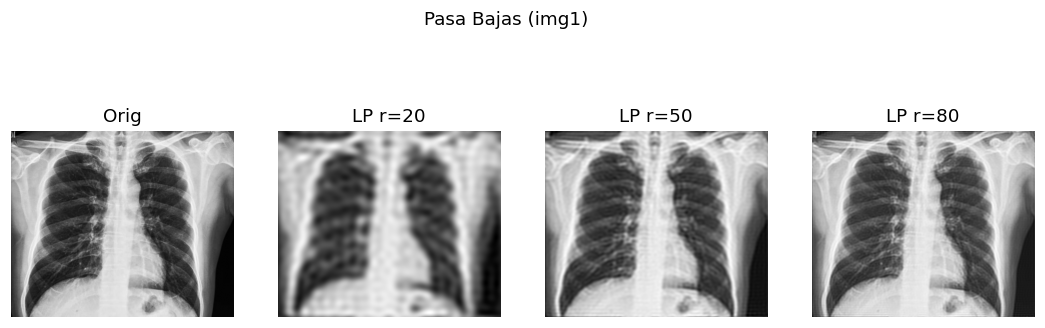

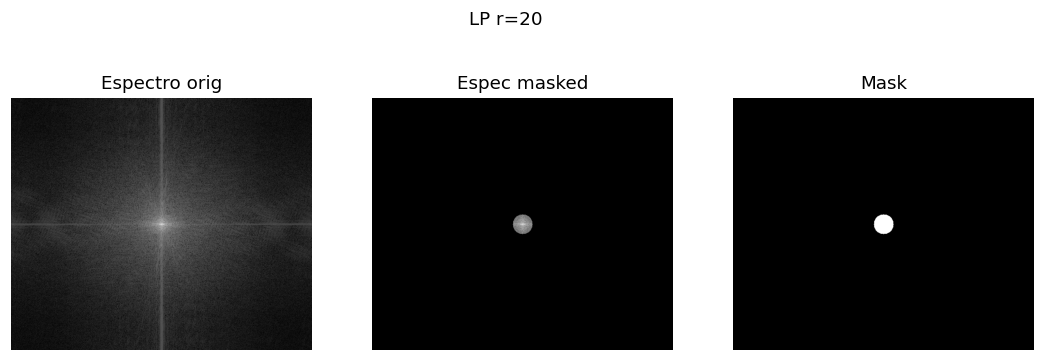

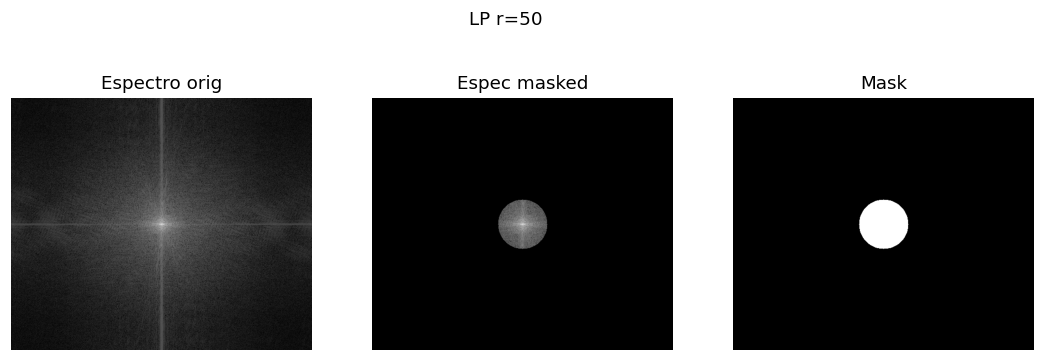

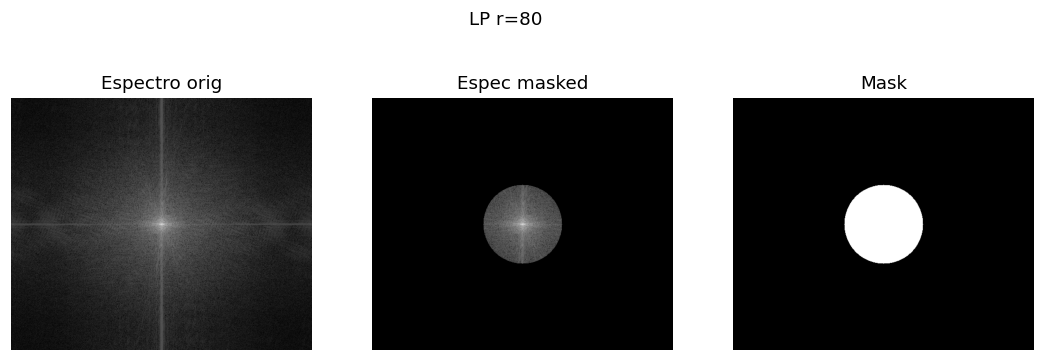

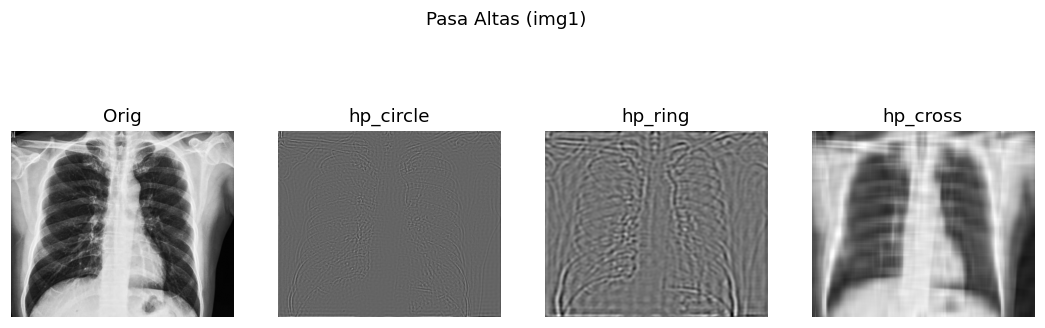

In [20]:
if img1 is not None:
    rows,cols=img1.shape; radios=[20,50,80]; radios=[min(max(3,r),min(rows,cols)//2-1) for r in radios]
    lp=[]
    for r in radios:
        imgb,M,Mm,mask=apply_freq(img1,circ_mask(img1.shape,r)); lp.append((r,imgb,M,Mm,mask))
    show([img1]+[x[1] for x in lp],['Orig']+[f'LP r={x[0]}' for x in lp], suptitle='Pasa Bajas (img1)')
    for r,imgb,M,Mm,mask in lp: show([M,Mm,mask],['Espectro orig','Espec masked','Mask'], suptitle=f'LP r={r}')
    hp_cfg={'hp_circle':1-circ_mask(img1.shape,radios[1]),'hp_ring':ring_mask(img1.shape,radios[0],radios[1]),'hp_cross':cross_mask(img1.shape,5)}
    hp_res={k:apply_freq(img1,v) for k,v in hp_cfg.items()}
    show([img1]+[hp_res[k][0] for k in hp_res],['Orig']+list(hp_res.keys()), suptitle='Pasa Altas (img1)')

Aplicando filtros en frecuencia a la segunda imagen


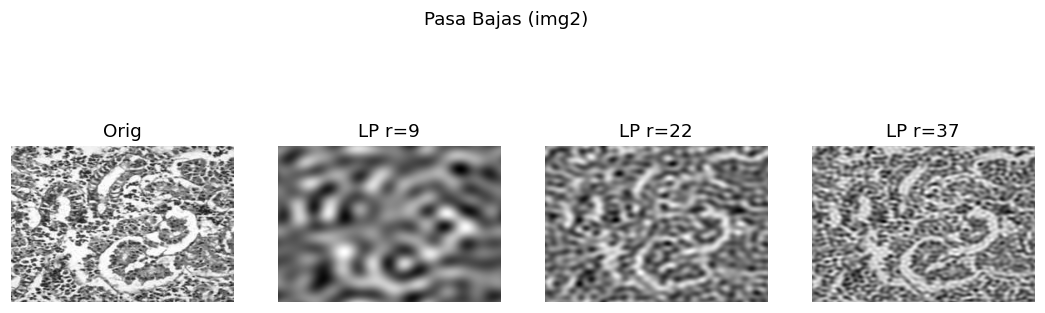

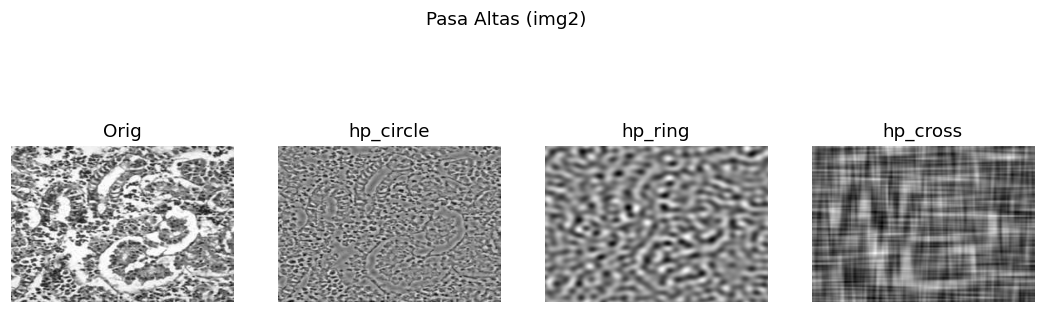

In [21]:
if img2 is not None:
    print('Aplicando filtros en frecuencia a la segunda imagen')
    rows2,cols2=img2.shape; radios2=[int(min(rows2,cols2)*0.05),int(min(rows2,cols2)*0.12),int(min(rows2,cols2)*0.2)]
    lp2=[]
    for r in radios2:
        imgb,M,Mm,mask=apply_freq(img2,circ_mask(img2.shape,r)); lp2.append((r,imgb,M,Mm,mask))
    show([img2]+[x[1] for x in lp2],['Orig']+[f'LP r={x[0]}' for x in lp2], suptitle='Pasa Bajas (img2)')
    hp2={'hp_circle':1-circ_mask(img2.shape,radios2[1]),'hp_ring':ring_mask(img2.shape,radios2[0],radios2[1]),'hp_cross':cross_mask(img2.shape,3)}
    hp2res={k:apply_freq(img2,v) for k,v in hp2.items()}
    show([img2]+[hp2res[k][0] for k in hp2res],['Orig']+list(hp2res.keys()), suptitle='Pasa Altas (img2)')